<a href="https://colab.research.google.com/github/Himanshuchaturvedi14/DSV_LAB-/blob/main/Himanshu_visulisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [73]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


In [74]:
conn = sqlite3.connect('/content/Ecom1check (1).sqlite')

In [75]:
customers = pd.read_sql_query("SELECT * FROM customers", conn)
orders = pd.read_sql_query("SELECT * FROM orders", conn)
products = pd.read_sql_query("SELECT * FROM products", conn)
payments = pd.read_sql_query("SELECT * FROM payments", conn)
order_items = pd.read_sql_query("SELECT * FROM order_items", conn)

In [76]:
display(customers.head())
display(orders.head())
display(products.head())
display(payments.head())
display(order_items.head())

,customer_id,customer_zip_code_prefix,customer_city,customer_state
0,I74lXDOfoqsp,6020,goiania,GO
1,47TuLHF2s7X5,23020,viamao,RS
2,dQ0dqI8Qwlj8,75094,campinas,SP
3,iQCmWhNkIczb,89284,santana de parnaiba,SP
4,Dp2g6JH8tO5Z,39810,aripuana,MT


,order_id,customer_id,order_purchase_timestamp,order_approved_at
0,u6rPMRAYIGig,I74lXDOfoqsp,2017-11-18 12:29:57.000000,2017-11-18 12:46:08.000000
1,ohY8f4FEbX19,47TuLHF2s7X5,2018-06-02 17:13:12.000000,2018-06-02 20:12:23.000000
2,I28liQek73i2,dQ0dqI8Qwlj8,2018-01-08 11:01:30.000000,2018-01-09 07:24:03.000000
3,bBG1T89mlY8W,iQCmWhNkIczb,2017-03-10 10:24:46.000000,2017-03-10 10:24:46.000000
4,CYxJJSQS8Lbo,Dp2g6JH8tO5Z,2017-12-02 10:04:07.000000,2017-12-05 04:13:30.000000


,product_id,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name
0,1slxdgbgWFax,50.0,16.0,5.0,11.0,toys
1,77PgsiElQLeB,200.0,21.0,7.0,14.0,electronics
2,QVlD26X1y7NI,1000.0,100.0,5.0,20.0,furniture_decor
3,yWlFGkKYfrpa,8950.0,40.0,30.0,40.0,toys
4,h6MCbrwh5kiC,2301.0,32.0,35.0,34.0,toys


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,u6rPMRAYIGig,1,credit_card,2,156.0
1,ohY8f4FEbX19,1,credit_card,1,4.0
2,I28liQek73i2,1,wallet,1,382.0
3,bBG1T89mlY8W,1,credit_card,3,15.0
4,CYxJJSQS8Lbo,1,wallet,1,284.0


,order_id,product_id,seller_id,price,shipping_charges
0,u6rPMRAYIGig,1slxdgbgWFax,3jwvL6ihC45G,24.0,21.0
1,ohY8f4FEbX19,77PgsiElQLeB,GlLj704QXlDB,43.0,12.0
2,I28liQek73i2,QVlD26X1y7NI,V3iKL8r9W9NR,50.0,67.0
3,bBG1T89mlY8W,yWlFGkKYfrpa,RNBdBKsXebna,89.0,62.0
4,CYxJJSQS8Lbo,h6MCbrwh5kiC,5Ja2lH0N2OZt,2140.0,9.0


                total_item_price  distinct_orders
customer_state                                   
SP                     5427808.0            16188
RJ                     1669256.0             5079
MG                     1508676.0             4378
RS                      829301.0             2184
PR                      711489.0             1905
SC                      464679.0             1406
BA                      442008.0             1275
DF                      288017.0              844
GO                      276987.0              740
ES                      263805.0              752


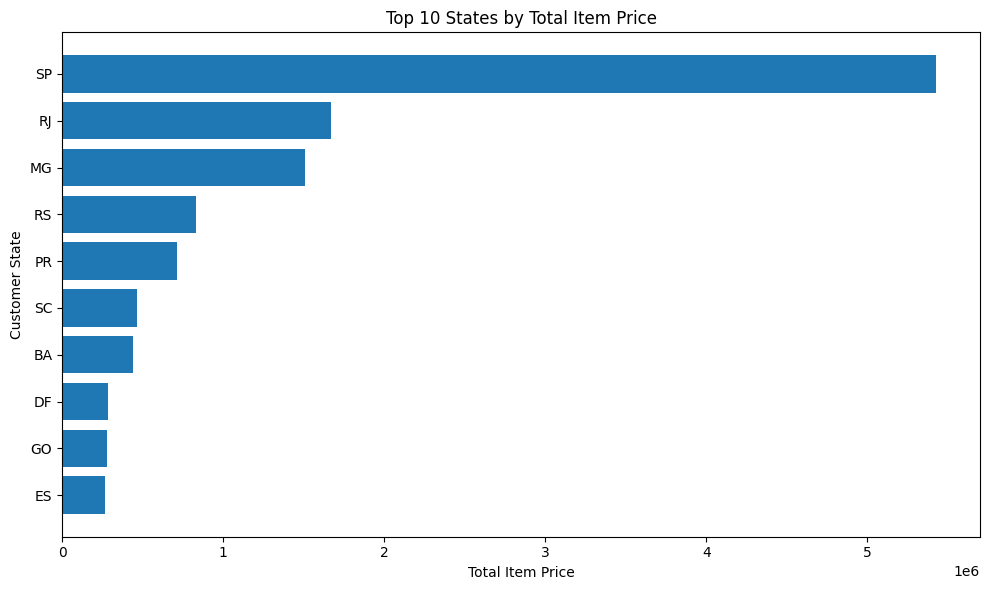

In [77]:
# Q1
df1 = customers[['customer_id', 'customer_state']].merge(
    orders[['order_id', 'customer_id']], on='customer_id'
)
df1 = df1.merge(
    order_items[['order_id', 'price']], on='order_id'
)
q1 = df1.groupby('customer_state').agg(
    total_item_price=('price', 'sum'),
    distinct_orders=('order_id', 'nunique')
).sort_values('total_item_price', ascending=False).head(10)
print(q1)
# Horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(q1.index, q1['total_item_price'])
plt.xlabel('Total Item Price')
plt.ylabel('Customer State')
plt.title('Top 10 States by Total Item Price')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [78]:
df2 =order_items.merge(products, on='product_id', how='left')

In [79]:
df2

,order_id,product_id,seller_id,price,shipping_charges,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name
0,u6rPMRAYIGig,1slxdgbgWFax,3jwvL6ihC45G,24.0,21.0,50.0,16.0,5.0,11.0,toys
1,ohY8f4FEbX19,77PgsiElQLeB,GlLj704QXlDB,43.0,12.0,200.0,21.0,7.0,14.0,electronics
2,I28liQek73i2,QVlD26X1y7NI,V3iKL8r9W9NR,50.0,67.0,1000.0,100.0,5.0,20.0,furniture_decor
3,bBG1T89mlY8W,yWlFGkKYfrpa,RNBdBKsXebna,89.0,62.0,8950.0,40.0,30.0,40.0,toys
4,CYxJJSQS8Lbo,h6MCbrwh5kiC,5Ja2lH0N2OZt,2140.0,9.0,2301.0,32.0,35.0,34.0,toys
...,...,...,...,...,...,...,...,...,...,...
38274,QKBW3XKevmfn,wr6barwyoaIE,XURInBuULfIO,99.0,38.0,200.0,16.0,28.0,11.0,toys
38275,Tjiw9bj8HtLr,sPZVXBD9lf3e,wR4cqCClYDyY,86.0,41.0,5150.0,22.0,3.0,22.0,toys
38276,mCPofb7A1aTq,Th6SHMsyTOMH,Gp2lLacVPwug,104.0,30.0,430.0,21.0,11.0,17.0,toys
38277,scVuqN10zbgb,PyjlDSHRGdSt,al4fWZ5NFQzG,224.0,75.0,1850.0,24.0,36.0,23.0,toys


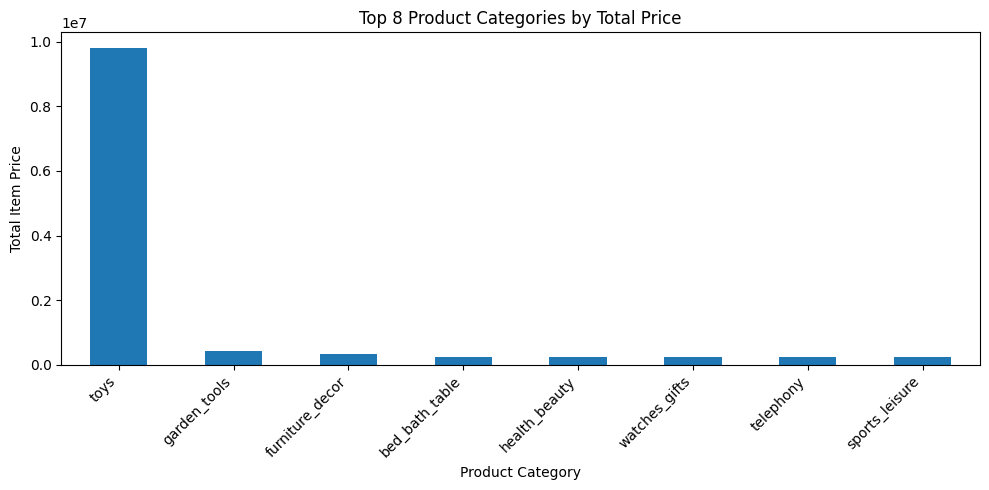

In [80]:
 #Q2
 df=order_items.merge(products,on='product_id',how='left')
df['product_category_name']=df['product_category_name'].fillna('Unknown')
top8=df.groupby('product_category_name')['price'].sum().nlargest(8)

top8.plot(kind='bar',figsize=(10,5),title='Top 8 Product Categories by Total Price')

plt.xlabel('Product Category')
plt.ylabel('Total Item Price')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
plt.show()

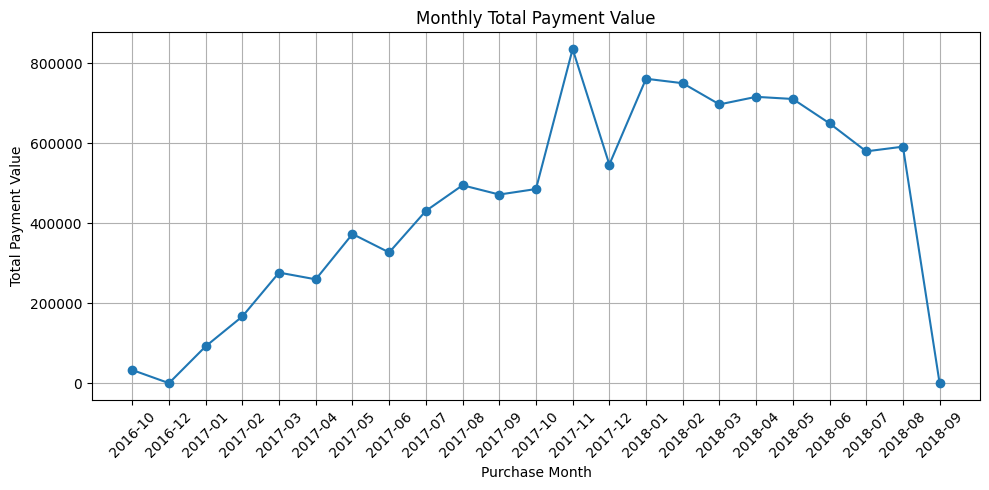

In [81]:
#Q3
payments=payments.merge(orders[['order_id','order_purchase_timestamp']],on='order_id',how='left')

payments['order_purchase_timestamp']=pd.to_datetime(payments['order_purchase_timestamp'])

payments['month']=payments['order_purchase_timestamp'].dt.to_period('M')

monthly_sales=payments.groupby('month')['payment_value'].sum().sort_index()

plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index.astype(str),monthly_sales.values,marker='o')
plt.xlabel('Purchase Month')
plt.ylabel('Total Payment Value')
plt.title('Monthly Total Payment Value')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

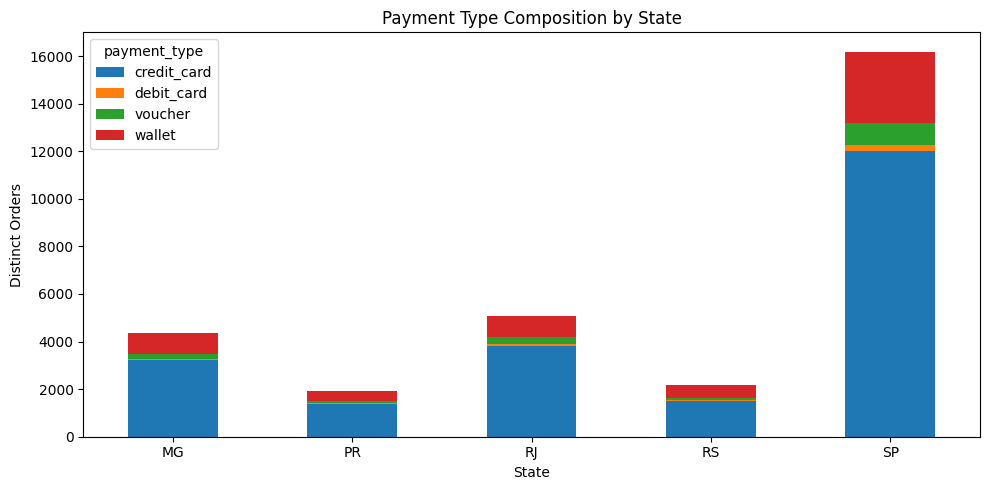

In [82]:
#Q4
df=orders.merge(customers,on='customer_id')
df=df.merge(payments,on='order_id')

top5=df.groupby('customer_state')['order_id'].nunique().nlargest(5).index

df=df[df['customer_state'].isin(top5)]

payment_data=df.groupby(['customer_state','payment_type'])['order_id'].nunique().unstack(fill_value=0)

payment_data.plot(kind='bar',stacked=True,figsize=(10,5),title='Payment Type Composition by State')

plt.xlabel('State')
plt.ylabel('Distinct Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

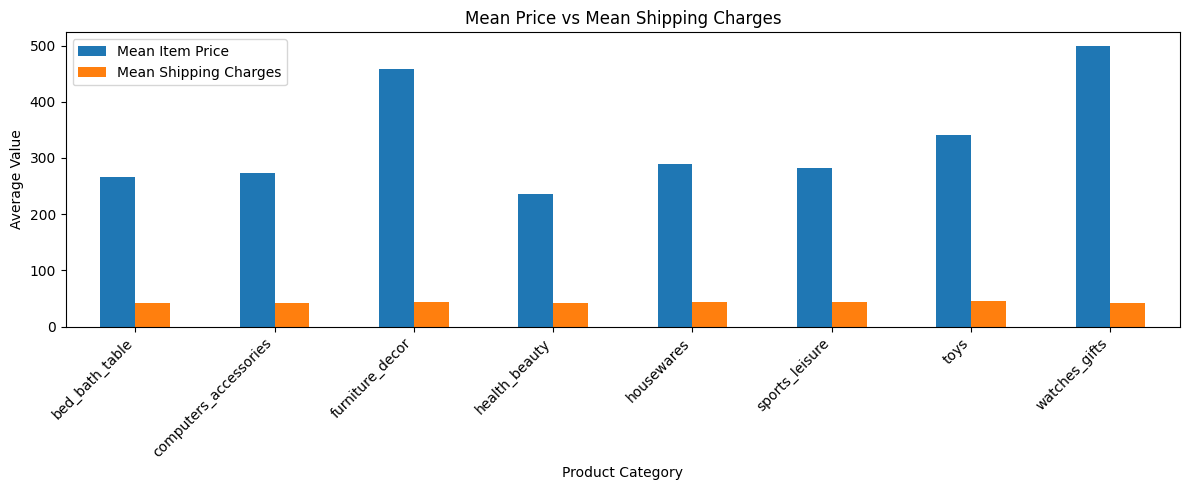

In [83]:

#Q5
import matplotlib.pyplot as plt

df=order_items.merge(products,on='product_id',how='left')
df['product_category_name']=df['product_category_name'].fillna('Unknown')

top8=df.groupby('product_category_name')['order_id'].nunique().nlargest(8).index

df=df[df['product_category_name'].isin(top8)]

data=df.groupby('product_category_name').agg(
    Mean_Price=('price','mean'),
    Mean_Shipping=('shipping_charges','mean')
)

data.plot(kind='bar',figsize=(12,5),title='Mean Price vs Mean Shipping Charges')

plt.xlabel('Product Category')
plt.ylabel('Average Value')
plt.xticks(rotation=45,ha='right')
plt.legend(['Mean Item Price','Mean Shipping Charges'])
plt.tight_layout()
plt.show()

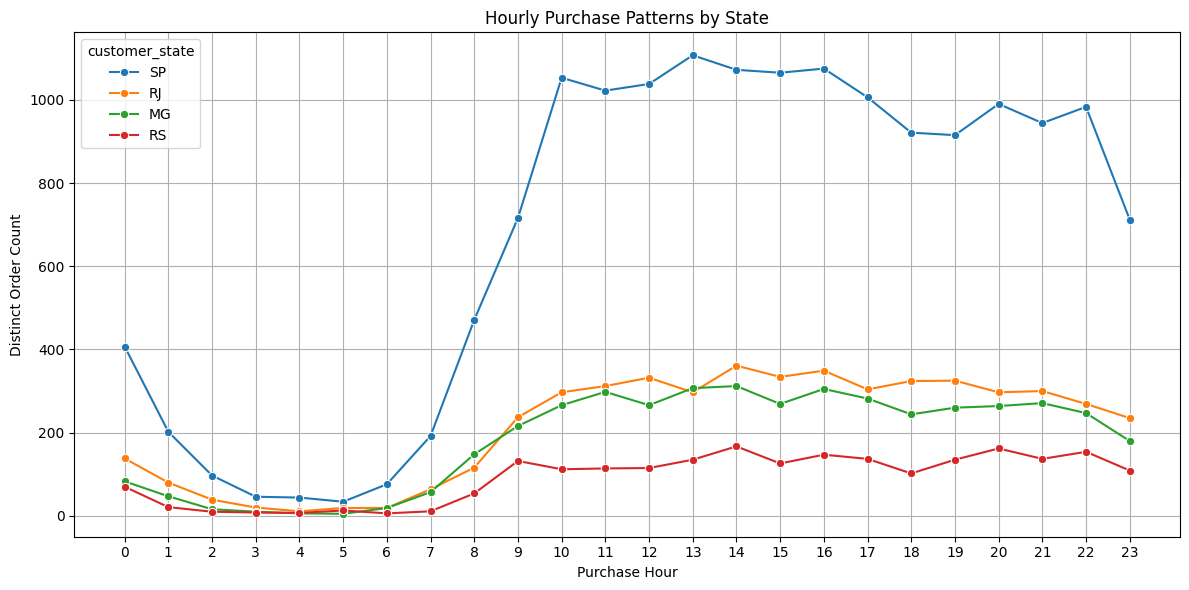

In [84]:
#Q6
df=orders.merge(customers,on='customer_id')

df['order_purchase_timestamp']=pd.to_datetime(df['order_purchase_timestamp'])
df['hour']=df['order_purchase_timestamp'].dt.hour

top4=df.groupby('customer_state')['order_id'].nunique().nlargest(4).index

df=df[df['customer_state'].isin(top4)]

hourly=df.groupby(['customer_state','hour'])['order_id'].nunique().reset_index()

idx=pd.MultiIndex.from_product([top4,range(24)],names=['customer_state','hour'])

hourly=hourly.set_index(['customer_state','hour']).reindex(idx,fill_value=0).reset_index()

plt.figure(figsize=(12,6))
sns.lineplot(data=hourly,x='hour',y='order_id',hue='customer_state',marker='o')

plt.title('Hourly Purchase Patterns by State')
plt.xlabel('Purchase Hour')
plt.ylabel('Distinct Order Count')
plt.xticks(range(24))
plt.grid()
plt.tight_layout()
plt.show()

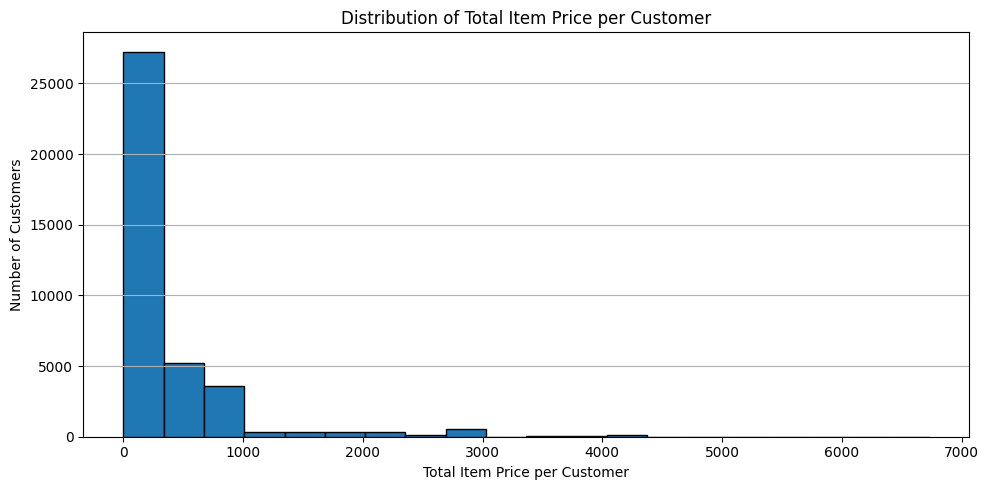

In [85]:
#Q7
customer_orders=orders[['order_id','customer_id']]

merged=order_items.merge(customer_orders,on='order_id',how='left')

customer_total=merged.groupby('customer_id')['price'].sum()

plt.figure(figsize=(10,5))
plt.hist(customer_total,bins=20,edgecolor='black')
plt.xlabel('Total Item Price per Customer')
plt.ylabel('Number of Customers')
plt.title('Distribution of Total Item Price per Customer')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

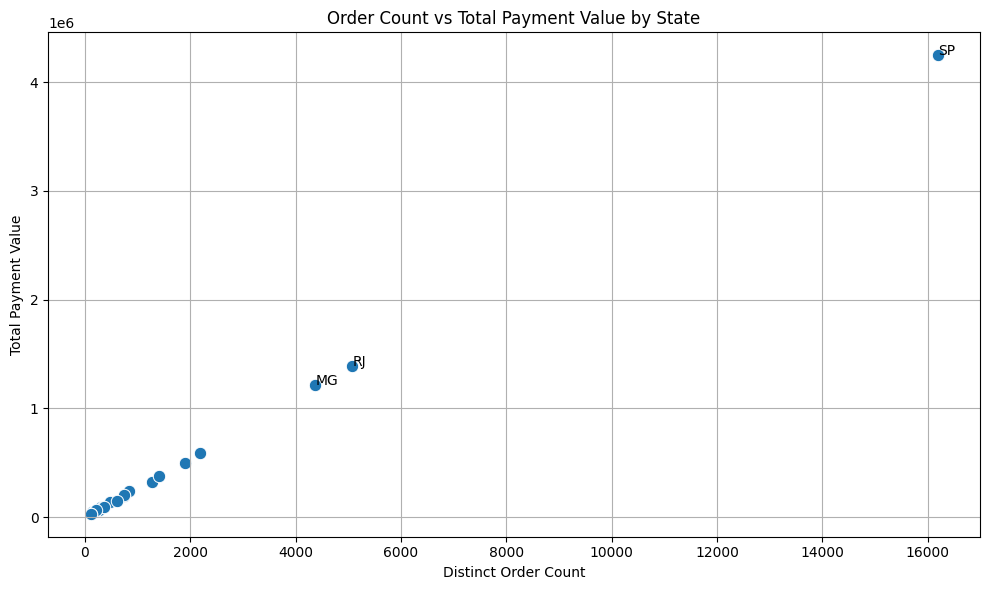

In [86]:
#Q8
state_orders=orders.merge(customers[['customer_id','customer_state']],on='customer_id',how='left')

order_count=state_orders.groupby('customer_state')['order_id'].nunique()

payment_data=payments.merge(state_orders[['order_id','customer_state']],on='order_id',how='left')

payment_total=payment_data.groupby('customer_state')['payment_value'].sum()

state_data=pd.DataFrame({
    'order_count':order_count,
    'payment_total':payment_total
}).reset_index()

state_data=state_data[state_data['order_count']>=100]

top3=state_data.nlargest(3,'payment_total')

plt.figure(figsize=(10,6))
sns.scatterplot(data=state_data,x='order_count',y='payment_total',s=80)

for i in range(len(top3)):
    plt.annotate(top3.iloc[i]['customer_state'],
                 (top3.iloc[i]['order_count'],top3.iloc[i]['payment_total']))

plt.xlabel('Distinct Order Count')
plt.ylabel('Total Payment Value')
plt.title('Order Count vs Total Payment Value by State')
plt.grid()
plt.tight_layout()
plt.show()

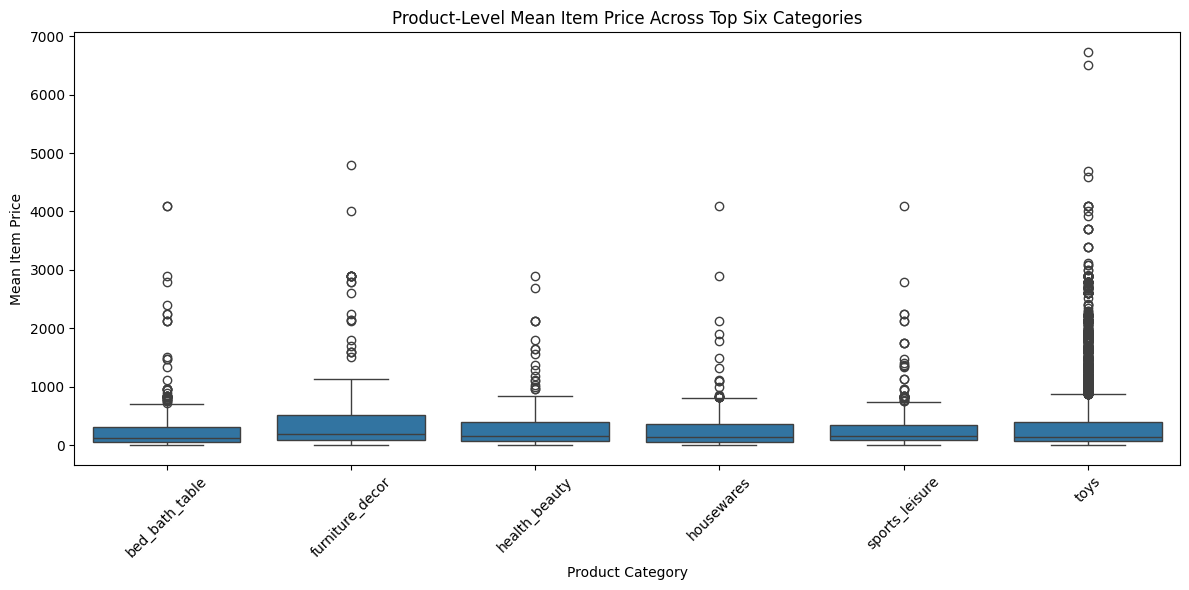

In [87]:
#Q9
product_data=order_items.merge(products[['product_id','product_category_name']],on='product_id',how='left')

product_data['product_category_name']=product_data['product_category_name'].fillna('Unknown')

product_mean=product_data.groupby(['product_category_name','product_id'])['price'].mean().reset_index()

top_categories=product_mean.groupby('product_category_name')['product_id'].nunique().nlargest(6).index

plot_data=product_mean[product_mean['product_category_name'].isin(top_categories)]

plt.figure(figsize=(12,6))
sns.boxplot(data=plot_data,x='product_category_name',y='price')

plt.xlabel('Product Category')
plt.ylabel('Mean Item Price')
plt.title('Product-Level Mean Item Price Across Top Six Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

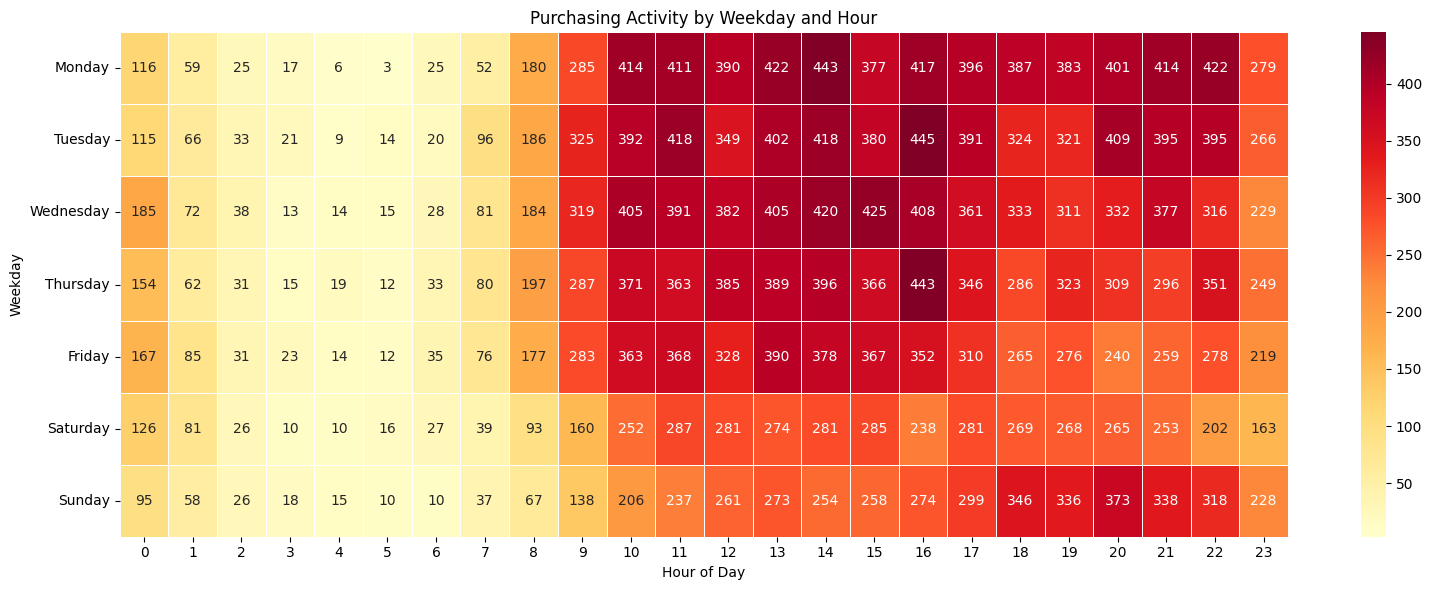

In [88]:
#Q10
orders['order_purchase_timestamp']=pd.to_datetime(orders['order_purchase_timestamp'])

orders['weekday']=orders['order_purchase_timestamp'].dt.day_name()
orders['hour']=orders['order_purchase_timestamp'].dt.hour

weekday_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

hourly_data=orders.groupby(['weekday','hour'])['order_id'].nunique().reset_index()

heatmap_data=hourly_data.pivot(index='weekday',columns='hour',values='order_id')

heatmap_data=heatmap_data.reindex(index=weekday_order,columns=range(24)).fillna(0)

plt.figure(figsize=(16,6))
sns.heatmap(heatmap_data,annot=True,fmt='.0f',cmap='YlOrRd',linewidths=0.5)

plt.xlabel('Hour of Day')
plt.ylabel('Weekday')
plt.title('Purchasing Activity by Weekday and Hour')
plt.tight_layout()
plt.show()

In [89]:
#Q11
volume_data=products.merge(order_items.groupby('product_id')['freight_value'].mean().reset_index(),on='product_id',how='left')

volume_data['product_category_name']=volume_data['product_category_name'].fillna('Unknown')
volume_data['volume']=volume_data['product_length_cm']*volume_data['product_height_cm']*volume_data['product_width_cm']

volume_data=volume_data[(volume_data['product_weight_g']>0)&(volume_data['volume']>0)]

category_volume=volume_data.groupby('product_category_name').agg(
    mean_volume=('volume','mean'),
    mean_shipping=('freight_value','mean'),
    mean_weight=('product_weight_g','mean')
).dropna()

plt.figure(figsize=(11,6))
sns.scatterplot(data=category_volume,x='mean_volume',y='mean_shipping',size='mean_weight',sizes=(30,400),legend=True)

for name,row in category_volume.iterrows():
    plt.annotate(name,(row['mean_volume'],row['mean_shipping']),fontsize=7)

plt.xlabel('Mean Product Volume')
plt.ylabel('Mean Shipping Charges')
plt.title('Category Volume vs Shipping Charges')
plt.tight_layout()
plt.show()

KeyError: 'Column not found: freight_value'

In [ ]:
#Q12
payment_year=payments.merge(orders[['order_id','order_purchase_timestamp']],on='order_id',how='left')

payment_year['order_purchase_timestamp']=pd.to_datetime(payment_year['order_purchase_timestamp'])
payment_year['year']=payment_year['order_purchase_timestamp'].dt.year

year_total=payment_year.groupby('year')['payment_value'].sum()
top_years=year_total.nlargest(2).index

year_payment=payment_year[payment_year['year'].isin(top_years)]

year_payment['period']=year_payment['year'].astype(str)

year_payment.groupby(['payment_type','period'])['payment_value'].sum().unstack(fill_value=0).plot(kind='bar',figsize=(10,6))

plt.xlabel('Payment Type')
plt.ylabel('Total Payment Value')
plt.title('Payment Type Totals for Top Two Years')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Available years:",payment_year.groupby('year')['order_purchase_timestamp'].agg(['min','max']))

In [ ]:
#Q13
state_payment=payments.merge(orders[['order_id','customer_id']],on='order_id',how='left')
state_payment=state_payment.merge(customers[['customer_id','customer_state']],on='customer_id',how='left')

top_states=state_payment.groupby('customer_state')['payment_value'].sum().nlargest(4).index

payment_colors=dict(zip(state_payment['payment_type'].unique(),plt.cm.tab10.colors))

fig,axes=plt.subplots(2,2,figsize=(12,10))

for ax,state in zip(axes.flatten(),top_states):
    data=state_payment[state_payment['customer_state']==state].groupby('payment_type')['payment_value'].sum()
    ax.pie(data,labels=data.index,autopct='%1.1f%%',colors=[payment_colors[x] for x in data.index])
    ax.set_title(state)

plt.suptitle('Payment Type Percentage by State')
plt.tight_layout()
plt.show()

In [ ]:
#Q14
orders['order_purchase_timestamp']=pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_approved_at']=pd.to_datetime(orders['order_approved_at'])

orders['approval_delay']=(orders['order_approved_at']-orders['order_purchase_timestamp']).dt.total_seconds()/3600

delay_data=orders.dropna(subset=['order_purchase_timestamp','order_approved_at'])
delay_data=delay_data[delay_data['approval_delay']>=0]

delay_data['month']=delay_data['order_purchase_timestamp'].dt.to_period('M')

monthly_delay=delay_data.groupby('month')['approval_delay'].median()
monthly_count=delay_data.groupby('month')['order_id'].nunique()

fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)

axes[0].plot(monthly_delay.index.astype(str),monthly_delay.values,marker='o')
axes[0].set_ylabel('Median Delay (Hours)')
axes[0].set_title('Monthly Median Approval Delay')

axes[1].bar(monthly_count.index.astype(str),monthly_count.values)
axes[1].set_ylabel('Valid Order Count')
axes[1].set_title('Orders with Valid Approval Delay')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Q15
city_data=orders.merge(customers[['customer_id','customer_city','customer_state']],on='customer_id',how='left')

city_data=city_data.merge(order_items[['order_id','price']],on='order_id',how='left')

city_total=city_data.groupby(['customer_city','customer_state']).agg(
    total_price=('price','sum'),
    order_count=('order_id','nunique')
).reset_index()

city_total=city_total[city_total['order_count']>=30]

top_cities=city_total.nlargest(10,'total_price')

top_cities['city_state']=top_cities['customer_city']+' ('+top_cities['customer_state']+')'

plt.figure(figsize=(11,6))
sns.barplot(data=top_cities,x='total_price',y='city_state')

plt.xlabel('Total Item Price')
plt.ylabel('City and State')
plt.title('Top 10 City-State Pairs by Item Price')
plt.tight_layout()
plt.show()

In [ ]:
#Q16
credit=payments[(payments['payment_type']=='credit_card')&(payments['payment_installments']>0)].copy()

credit=credit.merge(orders[['order_id','order_purchase_timestamp']],on='order_id',how='left')

credit['order_purchase_timestamp']=pd.to_datetime(credit['order_purchase_timestamp'])
credit['month']=credit['order_purchase_timestamp'].dt.to_period('M')

credit['installment_band']=pd.cut(
    credit['payment_installments'],
    bins=[0,1,3,6,float('inf')],
    labels=['1','2-3','4-6','7+']
)

monthly_credit=credit.groupby(['month','installment_band'],observed=False)['payment_value'].sum().unstack(fill_value=0)

monthly_credit.plot(kind='area',stacked=True,figsize=(12,6),alpha=0.8)

plt.xlabel('Month')
plt.ylabel('Payment Value')
plt.title('Monthly Credit Card Payment by Installment Band')
plt.tight_layout()
plt.show()

In [ ]:
#Q17
shipping_data=order_items.merge(products[['product_id','product_category_name']],on='product_id',how='left')

shipping_data['product_category_name']=shipping_data['product_category_name'].fillna('Unknown')

category_shipping=shipping_data.groupby('product_category_name').agg(
    total_shipping=('freight_value','sum'),
    total_price=('price','sum')
)

category_shipping=category_shipping[category_shipping['total_price']>0]

category_shipping['shipping_percentage']=(category_shipping['total_shipping']/category_shipping['total_price'])*100

top_shipping=category_shipping.nlargest(10,'shipping_percentage').sort_values('shipping_percentage')

plt.figure(figsize=(11,6))
plt.barh(top_shipping.index,top_shipping['shipping_percentage'])

plt.xlabel('Shipping Charge Percentage')
plt.ylabel('Category')
plt.title('Top 10 Categories by Shipping Charge Percentage')
plt.tight_layout()
plt.show()

In [ ]:
#Q18
weekday_payment=payments.merge(orders[['order_id','order_purchase_timestamp']],on='order_id',how='left')

weekday_payment['order_purchase_timestamp']=pd.to_datetime(weekday_payment['order_purchase_timestamp'])
weekday_payment['weekday']=weekday_payment['order_purchase_timestamp'].dt.day_name()

weekday_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

grouped=weekday_payment.groupby(['weekday','payment_type']).agg(
    mean_payment=('payment_value','mean'),
    order_count=('order_id','nunique')
).reset_index()

grouped=grouped[grouped['order_count']>=20]
grouped['weekday']=pd.Categorical(grouped['weekday'],categories=weekday_order,ordered=True)

plt.figure(figsize=(12,6))
sns.barplot(data=grouped,x='weekday',y='mean_payment',hue='payment_type',errorbar=None)

plt.xlabel('Weekday')
plt.ylabel('Mean Payment Value')
plt.title('Mean Payment Value by Weekday and Payment Type')
plt.tight_layout()
plt.show()

In [ ]:

#Q19
annual_orders=orders.copy()

annual_orders['order_purchase_timestamp']=pd.to_datetime(annual_orders['order_purchase_timestamp'])
annual_orders['year']=annual_orders['order_purchase_timestamp'].dt.year

annual_data=annual_orders[annual_orders['year'].isin([2016,2017,2018])]

annual_data=annual_data.drop_duplicates('order_id')

annual_data=annual_data.merge(order_items.groupby('order_id')['price'].sum().reset_index(),on='order_id',how='left')

annual_summary=annual_data.groupby('year').agg(
    total_item_price=('price','sum'),
    order_count=('order_id','nunique')
).reindex([2016,2017,2018])

fig,axes=plt.subplots(1,2,figsize=(12,5))

annual_summary['total_item_price'].plot(kind='bar',ax=axes[0])
axes[0].set_title('Annual Total Item Price')
axes[0].set_xlabel('Year')

annual_summary['order_count'].plot(kind='bar',ax=axes[1])
axes[1].set_title('Annual Distinct Order Count')
axes[1].set_xlabel('Year')

plt.tight_layout()
plt.show()

print("Observed periods:")
print(annual_orders.groupby('year')['order_purchase_timestamp'].agg(['min','max']))

In [ ]:
#Q20
payment_extracts={ptype:payments[payments['payment_type']==ptype].copy() for ptype in payments['payment_type'].dropna().unique()}

reconstructed=pd.concat(payment_extracts.values(),ignore_index=True)

payment_summary=reconstructed.groupby('payment_type').agg(
    total_payment=('payment_value','sum'),
    mean_installments=('payment_installments','mean')
)

fig,axes=plt.subplots(1,2,figsize=(12,5))

payment_summary['total_payment'].plot(kind='bar',ax=axes[0])
axes[0].set_title('Total Payment Value')

payment_summary['mean_installments'].plot(kind='bar',ax=axes[1])
axes[1].set_title('Mean Installment Count')

plt.tight_layout()
plt.show()

In [ ]:
#Q21
regional_customers={state:customers[customers['customer_state']==state].copy() for state in ['SP','RJ','MG']}

regional_data=pd.concat(regional_customers.values(),ignore_index=True)

regional_data=regional_data.merge(orders[['order_id','customer_id']],on='customer_id',how='left')

regional_data=regional_data.merge(order_items[['order_id','product_id','price']],on='order_id',how='left')

state_product=regional_data.groupby(['customer_state','product_id'])['price'].sum().reset_index()

plt.figure(figsize=(10,6))
sns.boxplot(data=state_product,x='customer_state',y='price')

plt.xlabel('State')
plt.ylabel('Total Item Price per Product')
plt.title('State-Wise Product Price Distribution')
plt.tight_layout()
plt.show()

In [ ]:
#Q22
toy_data=order_items.merge(products[['product_id','product_category_name']],on='product_id',how='left')

toy_data['group']=toy_data['product_category_name'].apply(lambda x:'Toys' if x=='brinquedos' else 'Other')

toy_summary=toy_data.groupby('group').agg(
    total_item_price=('price','sum'),
    order_count=('order_id','nunique'),
    mean_shipping=('freight_value','mean')
).reindex(['Toys','Other'])

fig,axes=plt.subplots(1,3,figsize=(15,5))

toy_summary['total_item_price'].plot(kind='bar',ax=axes[0],title='Total Item Price')
toy_summary['order_count'].plot(kind='bar',ax=axes[1],title='Distinct Order Count')
toy_summary['mean_shipping'].plot(kind='bar',ax=axes[2],title='Mean Shipping Charges')

plt.tight_layout()
plt.show()

In [ ]:
#Q23
quarter_data=orders.copy()

quarter_data['order_purchase_timestamp']=pd.to_datetime(quarter_data['order_purchase_timestamp'])
quarter_data['quarter']=quarter_data['order_purchase_timestamp'].dt.to_period('Q')

quarter_data=quarter_data.merge(order_items.groupby('order_id')['price'].sum().reset_index(),on='order_id',how='left')

quarter_summary=quarter_data.groupby('quarter').agg(
    total_price=('price','sum'),
    order_count=('order_id','nunique')
)

all_quarters=pd.period_range(quarter_summary.index.min(),quarter_summary.index.max(),freq='Q')

quarter_summary=quarter_summary.reindex(all_quarters)

quarter_summary['total_price'].plot(kind='line',marker='o',figsize=(12,5))

plt.xlabel('Year-Quarter')
plt.ylabel('Total Item Price')
plt.title('Quarterly Total Item Price')
plt.xticks(range(len(all_quarters)),all_quarters.astype(str),rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

print(quarter_summary)

In [ ]:
#Q24
wallet_orders=payments.copy()

wallet_orders['wallet_group']=wallet_orders['payment_type'].apply(
    lambda x:'Wallet' if x in ['digital_wallet','voucher'] else 'Non-Wallet'
)

wallet_orders=wallet_orders.merge(orders[['order_id','order_purchase_timestamp']],on='order_id',how='left')

wallet_orders['order_purchase_timestamp']=pd.to_datetime(wallet_orders['order_purchase_timestamp'])
wallet_orders['month']=wallet_orders['order_purchase_timestamp'].dt.to_period('M')

monthly_wallet=wallet_orders.groupby(['month','wallet_group'])['order_id'].nunique().unstack(fill_value=0)

monthly_share=monthly_wallet.div(monthly_wallet.sum(axis=1),axis=0)*100

monthly_share.plot(kind='bar',stacked=True,figsize=(13,6))

plt.xlabel('Month')
plt.ylabel('Percentage of Distinct Orders')
plt.title('Monthly Wallet vs Non-Wallet Order Shares')
plt.legend(title='Payment Group')
plt.tight_layout()
plt.show()

In [ ]:
#Q25
product_labels=products[['product_id','product_category_name']].copy()

even_extract=product_labels.iloc[::2].copy()
odd_extract=product_labels.iloc[1::2].copy()

even_labels=even_extract.set_index('product_id')['product_category_name']
odd_labels=odd_extract.set_index('product_id')['product_category_name']

recovered=products[['product_id']].copy().set_index('product_id')

recovered['category']=even_labels.combine_first(odd_labels)

recovered['category']=recovered['category'].fillna('Unknown')

recovered=recovered.reset_index()

price_data=order_items.merge(recovered,on='product_id',how='left')

category_summary=price_data.groupby('category').agg(
    product_count=('product_id','nunique'),
    total_price=('price','sum')
)

top_categories=category_summary.nlargest(10,'product_count')

fig,axes=plt.subplots(1,2,figsize=(14,6))

top_categories['product_count'].plot(kind='bar',ax=axes[0],title='Distinct Product Count')
top_categories['total_price'].plot(kind='bar',ax=axes[1],title='Total Item Price')

plt.tight_layout()
plt.show()

In [ ]:
#Q26
state_year=orders.copy()

state_year['order_purchase_timestamp']=pd.to_datetime(state_year['order_purchase_timestamp'])
state_year['year']=state_year['order_purchase_timestamp'].dt.year

state_year=state_year[state_year['year'].isin([2017,2018])]

state_year=state_year.merge(customers[['customer_id','customer_state']],on='customer_id',how='left')

state_year=state_year.merge(order_items.groupby('order_id')['price'].sum().reset_index(),on='order_id',how='left')

state_summary=state_year.groupby(['customer_state','year'])['price'].sum().unstack(fill_value=0)

state_summary['combined_total']=state_summary.sum(axis=1)

top_states=state_summary.nlargest(10,'combined_total')

top_states['combined_total'].sort_values().plot(kind='barh',figsize=(10,6))

plt.xlabel('Combined Item Price')
plt.ylabel('State')
plt.title('Top 10 States by Combined Item Price (2017-2018)')
plt.tight_layout()
plt.show()

In [ ]:
#Q27
weight_data=products[['product_id','product_weight_g']].copy()

even_weight=weight_data.iloc[::2].set_index('product_id')['product_weight_g']
odd_weight=weight_data.iloc[1::2].set_index('product_id')['product_weight_g']

recovered_weight=products[['product_id','product_category_name']].copy().set_index('product_id')

recovered_weight['weight']=even_weight.combine_first(odd_weight)

recovered_weight['product_category_name']=recovered_weight['product_category_name'].fillna('Unknown')

recovered_weight=recovered_weight.reset_index()

weight_orders=order_items.groupby('product_id').agg(
    mean_shipping=('freight_value','mean'),
    order_count=('order_id','nunique')
).reset_index()

weight_orders=weight_orders.merge(recovered_weight,on='product_id',how='left')

weight_orders=weight_orders[(weight_orders['weight']>0)&(weight_orders['mean_shipping']>0)]

top_categories=weight_orders.groupby('product_category_name')['order_count'].sum().nlargest(8).index

weight_plot=weight_orders[weight_orders['product_category_name'].isin(top_categories)]

category_weight=weight_plot.groupby('product_category_name').agg(
    mean_weight=('weight','mean'),
    mean_shipping=('mean_shipping','mean')
).reset_index()

plt.figure(figsize=(11,6))
sns.scatterplot(data=category_weight,x='mean_weight',y='mean_shipping',hue='product_category_name',s=100)

plt.xlabel('Mean Product Weight (g)')
plt.ylabel('Mean Shipping Charges')
plt.title('Category Mean Weight vs Shipping Charges')
plt.legend(bbox_to_anchor=(1.05,1),loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
#Q28
payment_month=payments.merge(orders[['order_id','order_purchase_timestamp']],on='order_id',how='left')

payment_month['order_purchase_timestamp']=pd.to_datetime(payment_month['order_purchase_timestamp'])

payment_month['year']=payment_month['order_purchase_timestamp'].dt.year
payment_month['month']=payment_month['order_purchase_timestamp'].dt.month

payment_month=payment_month[payment_month['year'].isin([2017,2018])]

monthly_total=payment_month.groupby(['year','month'])['payment_value'].sum().unstack(0)

monthly_total=monthly_total.dropna(subset=[2017,2018])

monthly_total['difference']=monthly_total[2018]-monthly_total[2017]

plt.figure(figsize=(11,6))
plt.bar(monthly_total.index,monthly_total['difference'])

plt.axhline(0,linewidth=1)
plt.xlabel('Calendar Month')
plt.ylabel('2018 - 2017 Payment Value')
plt.title('Monthly Payment Value Difference')
plt.xticks(range(1,13))
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [ ]:
#Q29
category_year=orders.copy()

category_year['order_purchase_timestamp']=pd.to_datetime(category_year['order_purchase_timestamp'])
category_year['year']=category_year['order_purchase_timestamp'].dt.year

category_year=category_year[category_year['year'].isin([2017,2018])]

category_year=category_year.merge(order_items[['order_id','product_id','price']],on='order_id',how='left')

category_year=category_year.merge(products[['product_id','product_category_name']],on='product_id',how='left')

category_year['product_category_name']=category_year['product_category_name'].fillna('Unknown')

year_mean=category_year.groupby(['product_category_name','year'])['price'].mean().unstack()

year_mean=year_mean.dropna(subset=[2017,2018])

year_mean['maximum']=year_mean[[2017,2018]].max(axis=1)

year_mean['year']=year_mean.apply(lambda x:'Tie' if x[2017]==x[2018] else ('2017' if x[2017]>x[2018] else '2018'),axis=1)

top_mean=year_mean.nlargest(10,'maximum').reset_index()

plt.figure(figsize=(11,6))
sns.barplot(data=top_mean,x='maximum',y='product_category_name',hue='year',errorbar=None)

plt.xlabel('Higher Annual Mean Item Price')
plt.ylabel('Category')
plt.title('Top 10 Categories by Paired Maximum Mean Price')
plt.tight_layout()
plt.show()

In [ ]:
#Q30
payment_orders=payments.merge(orders[['order_id','customer_id']],on='order_id',how='left')

payment_customers=payment_orders.merge(customers[['customer_id','customer_state']],on='customer_id',how='left')

sp_extract=payment_customers[payment_customers['customer_state']=='SP'].copy()

non_sp_extract=payment_customers[payment_customers['customer_state']!='SP'].copy()

reconstructed_payments=pd.concat([sp_extract,non_sp_extract],ignore_index=True)

print("Original payment records:",len(payments))
print("Reconstructed payment records:",len(reconstructed_payments))
print("Unique payment IDs:",reconstructed_payments['order_id'].nunique())

state_payment=reconstructed_payments.groupby('customer_state')['payment_value'].sum().sort_values(ascending=False)

top5=state_payment.head(5)

other=state_payment.iloc[5:].sum()

donut_data=pd.concat([top5,pd.Series({'Other':other})])

shares=donut_data/donut_data.sum()*100

print("Total percentage:",shares.sum())

plt.figure(figsize=(9,7))

plt.pie(shares,labels=shares.index,autopct='%1.1f%%',startangle=90,wedgeprops={'width':0.4})

plt.title('Payment Value Share of Top Five States and Other')
plt.tight_layout()
plt.show()